In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from keras.layers import Dense, Flatten,Conv2D,MaxPooling2D
from keras.models import Sequential
from keras.utils import to_categorical
from keras.datasets import mnist

In [ ]:
(X_train, y_train), (X_test, y_test) = mnist.load_data()

11490434/11490434 [==============================] - 1s 0us/step


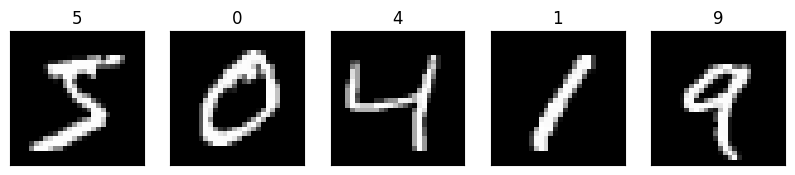

In [ ]:
# Display some images
fig, axes = plt.subplots(ncols=5, sharex=False,sharey=True, figsize=(10, 4))

for i in range(5):
    axes[i].set_title(y_train[i])
    axes[i].imshow(X_train[i], cmap='gray')
    axes[i].get_xaxis().set_visible(False)
    axes[i].get_yaxis().set_visible(False)
plt.show()

In [ ]:
# Convert y_train into one-hot format
temp = []
for i in range(len(y_train)):
    temp.append(to_categorical(y_train[i], num_classes=10))

y_train = np.array(temp)

In [ ]:
y_train

array([[0., 0., 0., ..., 0., 0., 0.],
       [1., 0., 0., ..., 0., 0., 0.],
       [0., 0., 0., ..., 0., 0., 0.],
       ...,
       [0., 0., 0., ..., 0., 0., 0.],
       [0., 0., 0., ..., 0., 0., 0.],
       [0., 0., 0., ..., 0., 1., 0.]], dtype=float32)

In [ ]:
# Convert y_test into one-hot format
temp = []
for i in range(len(y_test)):
    temp.append(to_categorical(y_test[i], num_classes=10))

y_test = np.array(temp)

In [ ]:
y_test

array([[0., 0., 0., ..., 1., 0., 0.],
       [0., 0., 1., ..., 0., 0., 0.],
       [0., 1., 0., ..., 0., 0., 0.],
       ...,
       [0., 0., 0., ..., 0., 0., 0.],
       [0., 0., 0., ..., 0., 0., 0.],
       [0., 0., 0., ..., 0., 0., 0.]], dtype=float32)

In [ ]:
# # Create simple Neural Network model
# model = Sequential()
# model.add(Flatten(input_shape=(28, 28)))
# model.add(Dense(5, activation='sigmoid'))
# model.add(Dense(10, activation='softmax'))
# model.summary()
#filters, kernel size, activation layes, image size, the convolution layer
model = Sequential()
model.add(Conv2D(32, (3, 3), activation='relu', input_shape=(28, 28,1)))
model.add(MaxPooling2D((2, 2)))
model.add(Conv2D(64, (3, 3), activation='relu'))
model.add(MaxPooling2D((2, 2)))
model.add(Conv2D(64, (3, 3), activation='relu'))
model.add(Flatten())
model.add(Dense(64, activation='sigmoid'))
model.add(Dense(10, activation='softmax'))

In [ ]:
model.compile(loss='categorical_crossentropy',optimizer='adam', metrics=['acc'])
# Train the Neural Network model
model.fit(X_train, y_train, epochs=5, validation_data=(X_test, y_test))

Epoch 1/5
1875/1875 [==============================] - 58s 30ms/step - loss: 0.2400 - acc: 0.9456 - val_loss: 0.0600 - val_acc: 0.9834
Epoch 2/5
1875/1875 [==============================] - 59s 32ms/step - loss: 0.0629 - acc: 0.9820 - val_loss: 0.0492 - val_acc: 0.9861
Epoch 3/5
1875/1875 [==============================] - 58s 31ms/step - loss: 0.0538 - acc: 0.9842 - val_loss: 0.0486 - val_acc: 0.9861
Epoch 4/5
1875/1875 [==============================] - 60s 32ms/step - loss: 0.0532 - acc: 0.9843 - val_loss: 0.0788 - val_acc: 0.9783
Epoch 5/5
1875/1875 [==============================] - 56s 30ms/step - loss: 0.0549 - acc: 0.9835 - val_loss: 0.0929 - val_acc: 0.9721


In [ ]:
# Making predictions using our trained model
predictions = model.predict(X_test)
predictions = np.argmax(predictions, axis=1)

313/313 [==============================] - 3s 9ms/step


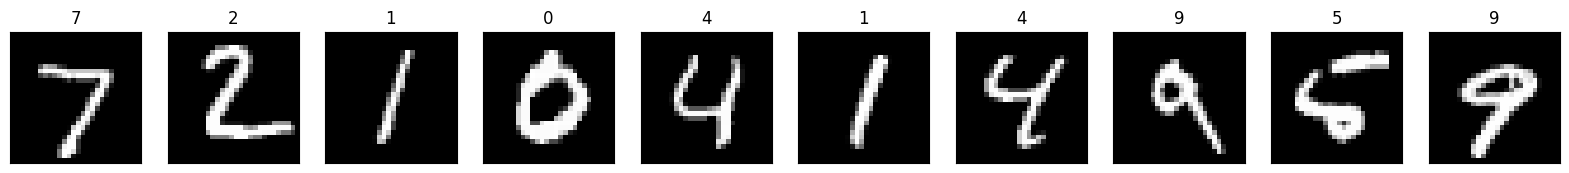

In [ ]:
# Display some predictions on test data
fig, axes = plt.subplots(ncols=10, sharex=False,
                         sharey=True, figsize=(20, 4))
for i in range(10):
    axes[i].set_title(predictions[i])
    axes[i].imshow(X_test[i], cmap='gray')
    axes[i].get_xaxis().set_visible(False)
    axes[i].get_yaxis().set_visible(False)
plt.show()